# 05 — Customer Analysis
## Superstore Customer Analytics

### Objetivo

Analisar o comportamento econômico dos clientes da Superstore, identificando diferenças de valor, concentração da receita e relação entre frequência de compra e valor gerado.

A análise será realizada no nível de cliente, complementando os resultados anteriores sem repetir a avaliação por segmentos de mercado.

## 1. Configuração e Base Analítica

### 1.1 — Configuração do Ambiente e Carregamento dos Dados

A análise utiliza a camada de dados processados criada nas etapas anteriores do projeto.

Nesta etapa, o objetivo é apenas configurar o ambiente, localizar a fonte analítica e carregar os dados necessários para a construção da visão por cliente.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from src.metrics import calculate_top_concentration


PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sales_data_clean.parquet"
)

print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Fonte analítica: {PROCESSED_DATA_PATH}")
print(f"Arquivo disponível: {PROCESSED_DATA_PATH.exists()}")

Raiz do projeto: c:\superstore-analytics
Fonte analítica: c:\superstore-analytics\data\processed\sales_data_clean.parquet
Arquivo disponível: True


In [2]:
df = pd.read_parquet(PROCESSED_DATA_PATH)

print(f"Registros carregados: {len(df):,}")
print(f"Colunas disponíveis: {df.shape[1]}")

Registros carregados: 9,799
Colunas disponíveis: 19


### 1.2 — Construção da Visão por Cliente

A base processada possui granularidade de item de pedido. Para analisar o comportamento econômico dos clientes, será construída uma visão agregada no nível de Customer ID.

Para cada cliente serão calculados:

- **Revenue:** receita total gerada pelo cliente;
- **Orders:** número de pedidos distintos realizados;
- **Average Order Value:** valor médio gerado por pedido.

Essa estrutura será a base das análises de valor, concentração e frequência de compra.

In [3]:
customer_summary = (
    df.groupby(
        ["Customer ID", "Customer Name"],
        as_index=False
    )
    .agg(
        Revenue=("Sales", "sum"),
        Orders=("Order ID", "nunique")
    )
)

customer_summary["Average_Order_Value"] = (
    customer_summary["Revenue"]
    / customer_summary["Orders"]
)

customer_summary.head()

,Customer ID,Customer Name,Revenue,Orders,Average_Order_Value
0,AA-10315,Alex Avila,5563.560,5,1112.712000
1,AA-10375,Allen Armold,1056.390,9,117.376667
2,AA-10480,Andrew Allen,1790.512,4,447.628000
3,AA-10645,Anna Andreadi,5086.935,6,847.822500
4,AB-10015,Aaron Bergman,886.156,3,295.385333


In [4]:
customer_validation = pd.DataFrame({
    "Validação": [
        "Clientes na visão analítica",
        "Customer IDs distintos",
        "Receita da visão por cliente",
        "Receita da base original",
        "Diferença de reconciliação"
    ],
    "Resultado": [
        f"{len(customer_summary):,}",
        f"{customer_summary['Customer ID'].nunique():,}",
        f"${customer_summary['Revenue'].sum():,.2f}",
        f"${df['Sales'].sum():,.2f}",
        f"${customer_summary['Revenue'].sum() - df['Sales'].sum():,.2f}"
    ]
})

customer_validation

,Validação,Resultado
0,Clientes na visão analítica,793
1,Customer IDs distintos,793
2,Receita da visão por cliente,"$2,261,255.41"
3,Receita da base original,"$2,261,255.41"
4,Diferença de reconciliação,$0.00


## 2. Valor dos Clientes

### 2.1 — Receita, Pedidos e Ticket Médio por Cliente

A avaliação do valor econômico dos clientes considera três perspectivas complementares: receita total gerada, número de pedidos realizados e ticket médio por pedido.

Essas métricas permitem distinguir clientes que geram maior receita por frequência de compra daqueles cujo valor está associado a pedidos de maior valor médio.

In [5]:
customer_metrics = (
    customer_summary[
        ["Revenue", "Orders", "Average_Order_Value"]
    ]
    .describe()
    .loc[["min", "25%", "50%", "75%", "max"]]
    .round(2)
)

customer_metrics

,Revenue,Orders,Average_Order_Value
min,4.83,1.0,2.42
25%,1081.47,4.0,210.88
50%,2215.00,6.0,361.66
75%,3670.26,8.0,560.34
max,25043.05,17.0,5008.61


#### Interpretação

A distribuição das métricas evidencia diferenças relevantes no valor econômico e no comportamento de compra entre os clientes.

Metade da base gerou até aproximadamente $2,22 mil em receita e realizou até 6 pedidos, enquanto o terceiro quartil alcançou cerca de $3,67 mil e 8 pedidos. No extremo superior, um cliente acumulou $25,04 mil em receita e o maior número observado chegou a 17 pedidos.

O ticket médio também apresenta forte amplitude: a mediana é de aproximadamente $361,66, enquanto o maior valor alcança $5,01 mil. Isso indica que frequência de compra e valor médio dos pedidos podem representar mecanismos distintos de geração de receita, relação que será investigada nas próximas etapas.

### 2.2 — Clientes de Maior Valor

O ranking por receita permite identificar os clientes com maior contribuição econômica acumulada.

Além da receita total, serão considerados o número de pedidos e o ticket médio, permitindo compreender diferentes mecanismos de geração de valor entre os clientes de maior relevância.

In [6]:
top_customers = (
    customer_summary
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_customers_display = top_customers.copy()

top_customers_display["Revenue"] = (
    top_customers_display["Revenue"]
    .map(lambda value: f"${value:,.2f}")
)

top_customers_display["Average_Order_Value"] = (
    top_customers_display["Average_Order_Value"]
    .map(lambda value: f"${value:,.2f}")
)

top_customers_display.index = (
    top_customers_display.index + 1
)

top_customers_display

,Customer ID,Customer Name,Revenue,Orders,Average_Order_Value
1,SM-20320,Sean Miller,"$25,043.05",5,"$5,008.61"
2,TC-20980,Tamara Chand,"$19,052.22",5,"$3,810.44"
3,RB-19360,Raymond Buch,"$15,117.34",6,"$2,519.56"
4,TA-21385,Tom Ashbrook,"$14,595.62",4,"$3,648.91"
5,AB-10105,Adrian Barton,"$14,473.57",10,"$1,447.36"
6,KL-16645,Ken Lonsdale,"$14,175.23",12,"$1,181.27"
7,SC-20095,Sanjit Chand,"$14,142.33",9,"$1,571.37"
8,HL-15040,Hunter Lopez,"$12,873.30",6,"$2,145.55"
9,SE-20110,Sanjit Engle,"$12,209.44",11,"$1,109.95"
10,CC-12370,Christopher Conant,"$12,129.07",5,"$2,425.81"


#### Interpretação

Os clientes de maior receita apresentam diferentes mecanismos de geração de valor.

**Sean Miller**, líder do ranking com $25,04 mil, realizou apenas 5 pedidos, mas apresentou ticket médio de aproximadamente $5,01 mil, indicando que sua posição é explicada principalmente pelo elevado valor médio das compras. Comportamento semelhante aparece em **Tamara Chand** e **Tom Ashbrook**, que também combinam poucos pedidos com tickets médios elevados.

Em contraste, clientes como **Ken Lonsdale** (12 pedidos), **Sanjit Engle** (11) e **Adrian Barton** (10) alcançaram posições relevantes por meio de maior frequência de compra, mesmo apresentando tickets médios consideravelmente inferiores aos primeiros colocados.

O ranking evidencia, portanto, que alta receita por cliente pode resultar de estratégias de compra distintas: **pedidos menos frequentes e de maior valor ou maior recorrência com valores médios menores**. Essa diferença será aprofundada posteriormente na análise entre frequência e valor gerado.

## 3. Concentração da Receita

### 3.1 — Participação dos Clientes na Receita

Após identificar os clientes de maior valor, a análise passa a avaliar o grau de concentração da receita na base de clientes.

O objetivo é verificar qual parcela da receita total é gerada pelos clientes economicamente mais relevantes, permitindo avaliar se o faturamento está amplamente distribuído ou concentrado em uma parcela menor da base.

In [7]:
customer_concentration = (
    customer_summary
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
    .copy()
)

total_customer_revenue = customer_concentration["Revenue"].sum()

customer_concentration["Revenue_Share"] = (
    customer_concentration["Revenue"]
    / total_customer_revenue
)

customer_concentration["Cumulative_Revenue_Share"] = (
    customer_concentration["Revenue_Share"].cumsum()
)

customer_concentration["Customer_Share"] = (
    (customer_concentration.index + 1)
    / len(customer_concentration)
)

In [8]:
customer_concentration_preview = customer_concentration[
    [
        "Customer ID",
        "Customer Name",
        "Revenue",
        "Customer_Share",
        "Cumulative_Revenue_Share"
    ]
].head().copy()

customer_concentration_preview["Revenue"] = (
    customer_concentration_preview["Revenue"]
    .map(lambda value: f"${value:,.2f}")
)

customer_concentration_preview["Customer_Share"] = (
    customer_concentration_preview["Customer_Share"]
    .map(lambda value: f"{value:.2%}")
)

customer_concentration_preview["Cumulative_Revenue_Share"] = (
    customer_concentration_preview["Cumulative_Revenue_Share"]
    .map(lambda value: f"{value:.2%}")
)

customer_concentration_preview

,Customer ID,Customer Name,Revenue,Customer_Share,Cumulative_Revenue_Share
0,SM-20320,Sean Miller,"$25,043.05",0.13%,1.11%
1,TC-20980,Tamara Chand,"$19,052.22",0.25%,1.95%
2,RB-19360,Raymond Buch,"$15,117.34",0.38%,2.62%
3,TA-21385,Tom Ashbrook,"$14,595.62",0.50%,3.26%
4,AB-10105,Adrian Barton,"$14,473.57",0.63%,3.90%


### 3.2 — Concentração entre os Clientes de Maior Valor

A concentração será avaliada pela participação na receita dos `10%` e `20%` de clientes com maior faturamento acumulado.

Essa abordagem permite quantificar quanto da receita depende das parcelas economicamente mais relevantes da base de clientes.

In [9]:

top_10 = calculate_top_concentration(
    customer_concentration["Revenue"],
    0.10
)

top_20 = calculate_top_concentration(
    customer_concentration["Revenue"],
    0.20
)

top_10_count = top_10["top_count"]
top_10_revenue = top_10["top_value"]
top_10_share = top_10["top_share"]

top_20_count = top_20["top_count"]
top_20_revenue = top_20["top_value"]
top_20_share = top_20["top_share"]

In [10]:
concentration_summary = pd.DataFrame({
    "Faixa": ["Top 10%", "Top 20%"],
    "Clientes": [top_10_count, top_20_count],
    "Receita": [top_10_revenue, top_20_revenue],
    "Participação na Receita": [top_10_share, top_20_share]
})

concentration_display = concentration_summary.copy()

concentration_display["Receita"] = (
    concentration_display["Receita"]
    .map(lambda value: f"${value:,.2f}")
)

concentration_display["Participação na Receita"] = (
    concentration_display["Participação na Receita"]
    .map(lambda value: f"{value:.2%}")
)

concentration_display

,Faixa,Clientes,Receita,Participação na Receita
0,Top 10%,80,"$704,697.12",31.16%
1,Top 20%,159,"$1,096,137.79",48.47%


#### Interpretação

A receita apresenta concentração relevante entre os clientes de maior valor, embora não esteja excessivamente dependente de uma parcela muito pequena da base.

Os 10% de clientes com maior receita, correspondentes a 80 clientes, geraram aproximadamente $704,70 mil, representando 31,16% da receita total. Ao ampliar a análise para os 20% de maior valor (159 clientes), a participação alcança 48,47%, equivalente a aproximadamente $1,10 milhão.

Isso significa que quase metade da receita está concentrada em aproximadamente um quinto da base de clientes. Ao mesmo tempo, os 80% restantes ainda respondem por pouco mais da metade do faturamento, indicando que a geração de receita permanece distribuída por uma parcela ampla da base.

A concentração observada reforça a relevância dos clientes de maior valor, mas não caracteriza dependência extrema de um pequeno grupo.

## 4. Frequência de Compra versus Valor Gerado

### 4.1 — Relação entre Frequência e Receita

A análise anterior mostrou que clientes de alta receita podem apresentar comportamentos distintos: alguns realizam muitos pedidos, enquanto outros alcançam elevado valor econômico com menor frequência de compra.

Nesta etapa, será avaliada a relação entre o número de pedidos realizados e a receita total gerada por cliente, permitindo verificar em que medida maior frequência de compra está associada a maior geração de receita.

In [11]:
pearson_corr = customer_summary[
    ["Orders", "Revenue"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = customer_summary[
    ["Orders", "Revenue"]
].corr(method="spearman").iloc[0, 1]

print(f"Correlação de Pearson: {pearson_corr:.3f}")
print(f"Correlação de Spearman: {spearman_corr:.3f}")

Correlação de Pearson: 0.419
Correlação de Spearman: 0.564


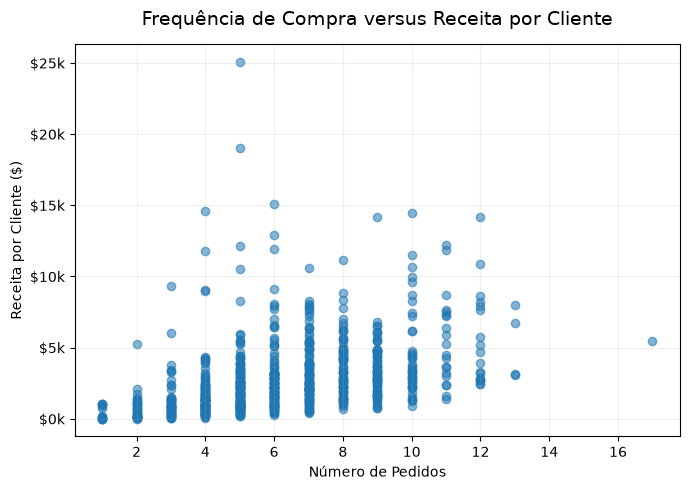

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    customer_summary["Orders"],
    customer_summary["Revenue"],
    alpha=0.55
)

ax.set_title(
    "Frequência de Compra versus Receita por Cliente",
    fontsize=14,
    pad=14
)

ax.set_xlabel("Número de Pedidos")
ax.set_ylabel("Receita por Cliente ($)")

ax.yaxis.set_major_formatter(
    lambda value, position: f"${value / 1000:,.0f}k"
)

ax.grid(
    axis="both",
    alpha=0.20
)

plt.tight_layout()
plt.show()

#### Interpretação

A relação entre frequência de compra e receita é positiva, mas apresenta dispersão relevante entre os clientes.

A correlação de Pearson (0,419) indica uma associação linear moderada entre número de pedidos e receita, enquanto a correlação de Spearman (0,564) mostra uma associação monotônica mais evidente. Em termos gerais, clientes com maior frequência de compra tendem a gerar mais receita, mas o número de pedidos, isoladamente, não explica o valor econômico de cada cliente.

O gráfico reforça essa diferença ao mostrar clientes com poucos pedidos e receitas excepcionalmente elevadas, ao mesmo tempo em que alguns clientes com alta frequência apresentam receitas mais moderadas.

Esses resultados confirmam que **frequência e valor dos pedidos atuam conjuntamente na geração de receita**, justificando a identificação de diferentes perfis econômicos de clientes na próxima etapa.

### 4.2 — Perfis Econômicos de Clientes

A relação entre frequência e receita mostrou que clientes podem gerar valor por mecanismos distintos.

Para representar esses comportamentos de forma objetiva, os clientes serão classificados a partir de duas dimensões: **frequência de compra** e **ticket médio por pedido**.

As medianas da própria base serão utilizadas como pontos de referência, permitindo distinguir quatro perfis econômicos sem estabelecer limites arbitrários externos.

In [13]:
median_orders = customer_summary["Orders"].median()
median_aov = customer_summary["Average_Order_Value"].median()

print(f"Mediana de pedidos: {median_orders:.0f}")
print(f"Mediana do ticket médio: ${median_aov:,.2f}")

Mediana de pedidos: 6
Mediana do ticket médio: $361.66


In [14]:
def classify_customer(row):
    high_frequency = row["Orders"] >= median_orders
    high_aov = row["Average_Order_Value"] >= median_aov

    if high_frequency and high_aov:
        return "Alta Frequência | Alto Ticket"

    if high_frequency and not high_aov:
        return "Alta Frequência | Menor Ticket"

    if not high_frequency and high_aov:
        return "Menor Frequência | Alto Ticket"

    return "Menor Frequência | Menor Ticket"


customer_summary["Economic_Profile"] = (
    customer_summary.apply(classify_customer, axis=1)
)

In [15]:
profile_summary = (
    customer_summary
    .groupby("Economic_Profile", as_index=False)
    .agg(
        Customers=("Customer ID", "nunique"),
        Revenue=("Revenue", "sum"),
        Average_Orders=("Orders", "mean"),
        Average_Order_Value=("Average_Order_Value", "mean")
    )
)

profile_summary["Customer_Share"] = (
    profile_summary["Customers"]
    / profile_summary["Customers"].sum()
)

profile_summary["Revenue_Share"] = (
    profile_summary["Revenue"]
    / profile_summary["Revenue"].sum()
)

profile_summary = (
    profile_summary
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)

In [16]:
profile_display = profile_summary.copy()

profile_display["Revenue"] = (
    profile_display["Revenue"]
    .map(lambda value: f"${value:,.2f}")
)

profile_display["Average_Orders"] = (
    profile_display["Average_Orders"]
    .map(lambda value: f"{value:.1f}")
)

profile_display["Average_Order_Value"] = (
    profile_display["Average_Order_Value"]
    .map(lambda value: f"${value:,.2f}")
)

profile_display["Customer_Share"] = (
    profile_display["Customer_Share"]
    .map(lambda value: f"{value:.2%}")
)

profile_display["Revenue_Share"] = (
    profile_display["Revenue_Share"]
    .map(lambda value: f"{value:.2%}")
)

profile_display

,Economic_Profile,Customers,Revenue,Average_Orders,Average_Order_Value,Customer_Share,Revenue_Share
0,Alta Frequência | Alto Ticket,239,"$1,227,696.72",7.9,$655.73,30.14%,54.29%
1,Menor Frequência | Alto Ticket,158,"$507,781.25",4.0,$798.96,19.92%,22.46%
2,Alta Frequência | Menor Ticket,210,"$392,311.78",8.0,$229.86,26.48%,17.35%
3,Menor Frequência | Menor Ticket,186,"$133,465.66",3.8,$178.39,23.46%,5.90%


#### Interpretação

A classificação evidencia diferenças relevantes na forma como os clientes geram valor para o negócio.

O perfil **Alta Frequência | Alto Ticket** reúne 239 clientes (30,14% da base) e concentra 54,29% da receita total, aproximadamente $1,23 milhão. Esse grupo combina recorrência elevada, com média de 7,9 pedidos, e ticket médio de aproximadamente $655,73, constituindo o perfil de maior contribuição econômica.

Os clientes de **Menor Frequência | Alto Ticket** representam 19,92% da base, mas geram 22,46% da receita. Apesar da menor frequência média (4,0 pedidos), apresentam o maior ticket médio entre os perfis ($798,96), mostrando que compras menos recorrentes podem manter elevada relevância econômica quando possuem maior valor.

Em contraste, o perfil **Alta Frequência | Menor Ticket** corresponde a 26,48% dos clientes, mas representa apenas 17,35% da receita. Isso reforça que frequência elevada, isoladamente, não implica maior geração de valor.

Por fim, **Menor Frequência | Menor Ticket** reúne 23,46% da base e responde por apenas 5,90% da receita, configurando o grupo de menor contribuição econômica relativa.

Os resultados confirmam que a geração de receita depende da combinação entre **frequência de compra e valor médio dos pedidos**, e não apenas de uma dessas dimensões isoladamente.

## 5. Síntese da Análise de Clientes

### 5.1 — Principais Achados

A análise no nível de cliente mostrou que a geração de receita ocorre por diferentes combinações entre frequência de compra e valor médio dos pedidos.

- **Os clientes de maior receita não apresentam um único padrão de comportamento.** Alguns alcançam elevado valor econômico por meio de tickets médios elevados e poucos pedidos, enquanto outros dependem de maior frequência de compra.

- **A receita apresenta concentração relevante, mas não extrema.** Os 10% de clientes de maior valor representam 31,16% da receita, enquanto os 20% superiores concentram 48,47%. Isso indica que os clientes de maior valor possuem peso significativo, mas uma parcela ampla da base continua contribuindo para o faturamento.

- **Frequência de compra está positivamente associada à receita, mas não determina isoladamente o valor do cliente.** As correlações de Pearson (0,419) e Spearman (0,564) mostram associação positiva, enquanto a dispersão observada evidencia diferenças relevantes entre clientes com frequências semelhantes.

- **A combinação entre alta frequência e alto ticket concentra a maior geração de valor.** Esse perfil representa 30,14% dos clientes, mas responde por 54,29% da receita total.

- **O ticket médio mostrou forte relevância na diferenciação econômica da base.** Os dois perfis classificados como Alto Ticket representam aproximadamente 50,06% dos clientes e, em conjunto, concentram 76,75% da receita.

Em conjunto, os resultados mostram que o valor econômico dos clientes não deve ser avaliado apenas pela frequência de compra. A combinação entre recorrência e valor médio dos pedidos oferece uma visão mais completa sobre os diferentes mecanismos de geração de receita na base de clientes.